In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url='/content/mymoviedb.csv'
dataset=pd.read_csv(url, engine='python', on_bad_lines='warn')

In [ ]:
display(dataset.head())
display(dataset.info())

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   object 
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   object 
 5   Vote_Average       9827 non-null   object 
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(1), object(8)
memory usage: 691.8+ KB


None

In [ ]:
dataset.isnull().sum()

,0
Release_Date,0
Title,9
Overview,9
Popularity,10
Vote_Count,10
Vote_Average,10
Original_Language,10
Genre,11
Poster_Url,11


In [ ]:
for i in dataset.columns:
  if dataset[i].dtypes==object:
    dataset[i]=dataset[i].fillna(dataset[i].mode()[0])
  else:
    dataset[i]=dataset[i].fillna(dataset[i].mean())

In [ ]:
dataset.isnull().sum()

,0
Release_Date,0
Title,0
Overview,0
Popularity,0
Vote_Count,0
Vote_Average,0
Original_Language,0
Genre,0
Poster_Url,0


In [ ]:
dataset.duplicated().sum()

np.int64(0)

In [ ]:
dataset.columns

Index(['Release_Date', 'Title', 'Overview', 'Popularity', 'Vote_Count',
       'Vote_Average', 'Original_Language', 'Genre', 'Poster_Url'],
      dtype='object')

In [ ]:
dataset["Genre"].value_counts().head(5)

,count
Genre,
Drama,477
Comedy,403
"Drama, Romance",248
Horror,238
"Horror, Thriller",199


In [ ]:
dataset.drop(columns=['Overview','Original_Language','Poster_Url'],inplace=True)

In [ ]:
dataset.columns

Index(['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average',
       'Genre'],
      dtype='object')

In [ ]:
dataset['Release_Date'] = pd.to_datetime(dataset['Release_Date'], errors='coerce')
dataset['Release_Date'].dtype

dtype('<M8[ns]')

In [ ]:
dataset['Release_Date']=dataset['Release_Date'].dt.year.astype('Int64')
dataset["Release_Date"].dtypes

Int64Dtype()

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Release_Date  9827 non-null   Int64  
 1   Title         9837 non-null   object 
 2   Popularity    9837 non-null   float64
 3   Vote_Count    9837 non-null   object 
 4   Vote_Average  9837 non-null   object 
 5   Genre         9837 non-null   object 
dtypes: Int64(1), float64(1), object(4)
memory usage: 470.8+ KB


In [ ]:
dataset['Vote_Count'] = pd.to_numeric(dataset['Vote_Count'], errors='coerce')
dataset['Vote_Average'] = pd.to_numeric(dataset['Vote_Average'], errors='coerce')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Release_Date  9827 non-null   Int64  
 1   Title         9837 non-null   object 
 2   Popularity    9837 non-null   float64
 3   Vote_Count    9836 non-null   float64
 4   Vote_Average  9836 non-null   float64
 5   Genre         9837 non-null   object 
dtypes: Int64(1), float64(3), object(2)
memory usage: 470.8+ KB


In [ ]:
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,"Action, Adventure, Science Fiction"
1,2022,The Batman,3827.658,1151.0,8.1,"Crime, Mystery, Thriller"
2,2022,No Exit,2618.087,122.0,6.3,Thriller
3,2021,Encanto,2402.201,5076.0,7.7,"Animation, Comedy, Family, Fantasy"
4,2021,The King's Man,1895.511,1793.0,7.0,"Action, Adventure, Thriller, War"


In [ ]:
dataset.isnull().sum()


,0
Release_Date,10
Title,0
Popularity,0
Vote_Count,1
Vote_Average,1
Genre,0


In [ ]:
dataset['Quality']=pd.cut(dataset['Vote_Average'],bins=[0,3,5,7,10],labels=['Not_Popular','Below_Average','Average','Popular'])

In [ ]:
# Fill nulls in numerical columns with the mean
dataset['Release_Date'].fillna(round(dataset['Release_Date'].mean()), inplace=True)
dataset['Vote_Count'].fillna(dataset['Vote_Count'].mean(), inplace=True)
dataset['Vote_Average'].fillna(dataset['Vote_Average'].mean(), inplace=True)

# Fill nulls in the categorical 'Quality' column with the mode
dataset['Quality'].fillna(dataset['Quality'].mode()[0], inplace=True)

# Verify that nulls have been filled
display(dataset.isnull().sum())

/tmp/ipython-input-2096077803.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Release_Date'].fillna(round(dataset['Release_Date'].mean()), inplace=True)
/tmp/ipython-input-2096077803.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].m

,0
Release_Date,0
Title,0
Popularity,0
Vote_Count,0
Vote_Average,0
Genre,0
Quality,0


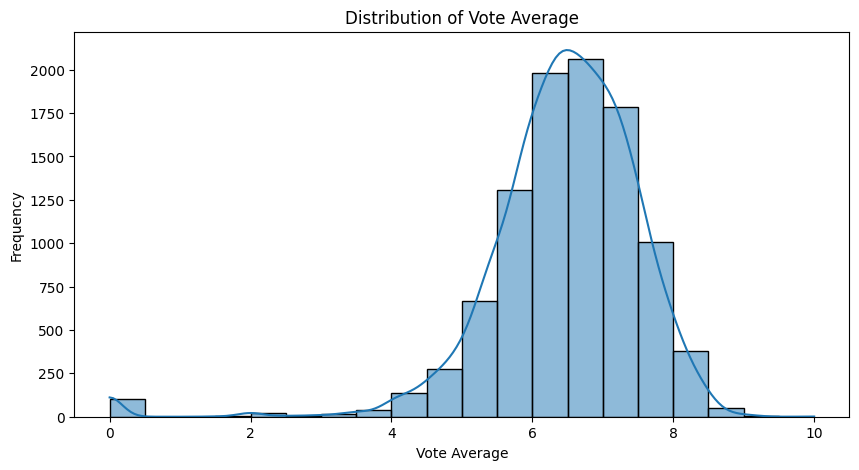

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(x=dataset["Vote_Average"], bins=20, kde=True)
plt.title('Distribution of Vote Average')
plt.xlabel('Vote Average')
plt.ylabel('Frequency')
plt.show()

In [ ]:
dataset.head(5)

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,"Action, Adventure, Science Fiction",Popular
1,2022,The Batman,3827.658,1151.0,8.1,"Crime, Mystery, Thriller",Popular
2,2022,No Exit,2618.087,122.0,6.3,Thriller,Average
3,2021,Encanto,2402.201,5076.0,7.7,"Animation, Comedy, Family, Fantasy",Popular
4,2021,The King's Man,1895.511,1793.0,7.0,"Action, Adventure, Thriller, War",Average


<Axes: xlabel='Quality', ylabel='count'>

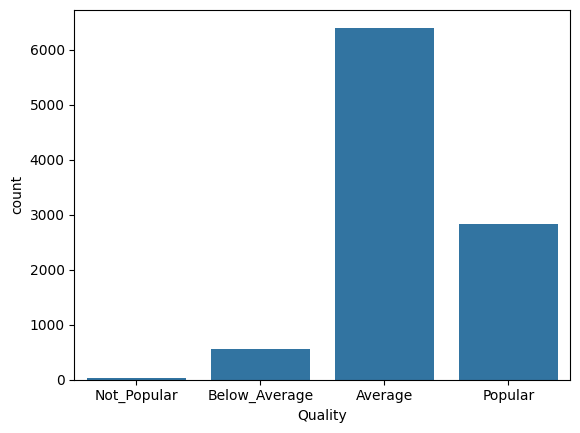

In [ ]:
sns.countplot(x=dataset['Quality'])

In [ ]:
dataset["Quality"].value_counts()

,count
Quality,
Average,6406
Popular,2839
Below_Average,561
Not_Popular,31


In [ ]:
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,"Action, Adventure, Science Fiction",Popular
1,2022,The Batman,3827.658,1151.0,8.1,"Crime, Mystery, Thriller",Popular
2,2022,No Exit,2618.087,122.0,6.3,Thriller,Average
3,2021,Encanto,2402.201,5076.0,7.7,"Animation, Comedy, Family, Fantasy",Popular
4,2021,The King's Man,1895.511,1793.0,7.0,"Action, Adventure, Thriller, War",Average


In [ ]:
dataset['Genre']=dataset['Genre'].str.split(', ')
dataset=dataset.explode('Genre').reset_index(drop=True)
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Action,Popular
1,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Adventure,Popular
2,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Science Fiction,Popular
3,2022,The Batman,3827.658,1151.0,8.1,Crime,Popular
4,2022,The Batman,3827.658,1151.0,8.1,Mystery,Popular


In [ ]:
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Action,Popular
1,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Adventure,Popular
2,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Science Fiction,Popular
3,2022,The Batman,3827.658,1151.0,8.1,Crime,Popular
4,2022,The Batman,3827.658,1151.0,8.1,Mystery,Popular


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25803 entries, 0 to 25802
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Release_Date  25803 non-null  Int64   
 1   Title         25803 non-null  object  
 2   Popularity    25803 non-null  float64 
 3   Vote_Count    25803 non-null  float64 
 4   Vote_Average  25803 non-null  float64 
 5   Genre         25803 non-null  object  
 6   Quality       25803 non-null  category
dtypes: Int64(1), category(1), float64(3), object(2)
memory usage: 1.2+ MB


In [ ]:
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Action,Popular
1,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Adventure,Popular
2,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Science Fiction,Popular
3,2022,The Batman,3827.658,1151.0,8.1,Crime,Popular
4,2022,The Batman,3827.658,1151.0,8.1,Mystery,Popular


In [ ]:
dataset['Genre'].unique()

array(['Action', 'Adventure', 'Science Fiction', 'Crime', 'Mystery',
       'Thriller', 'Animation', 'Comedy', 'Family', 'Fantasy', 'War',
       'Horror', 'Drama', 'Music', 'Romance', 'Western', 'History',
       'TV Movie', 'Documentary'], dtype=object)

In [ ]:
data=dataset['Genre'].value_counts()

/tmp/ipython-input-2171103071.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data,bins=20)


<Axes: xlabel='count', ylabel='Density'>

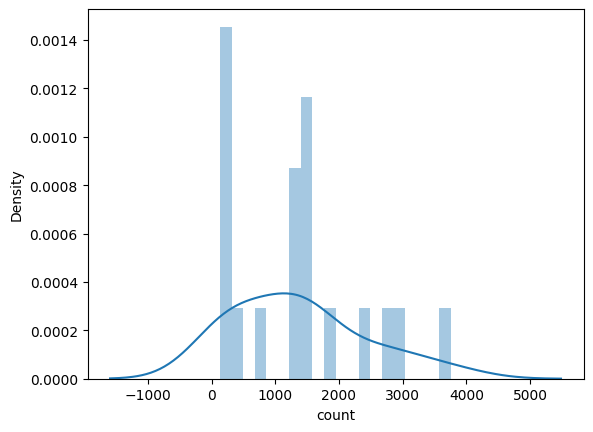

In [ ]:
sns.distplot(data,bins=20)

In [ ]:
dataset['Genre'].describe()

,Genre
count,25803
unique,19
top,Drama
freq,3755


<Axes: xlabel='count', ylabel='Genre'>

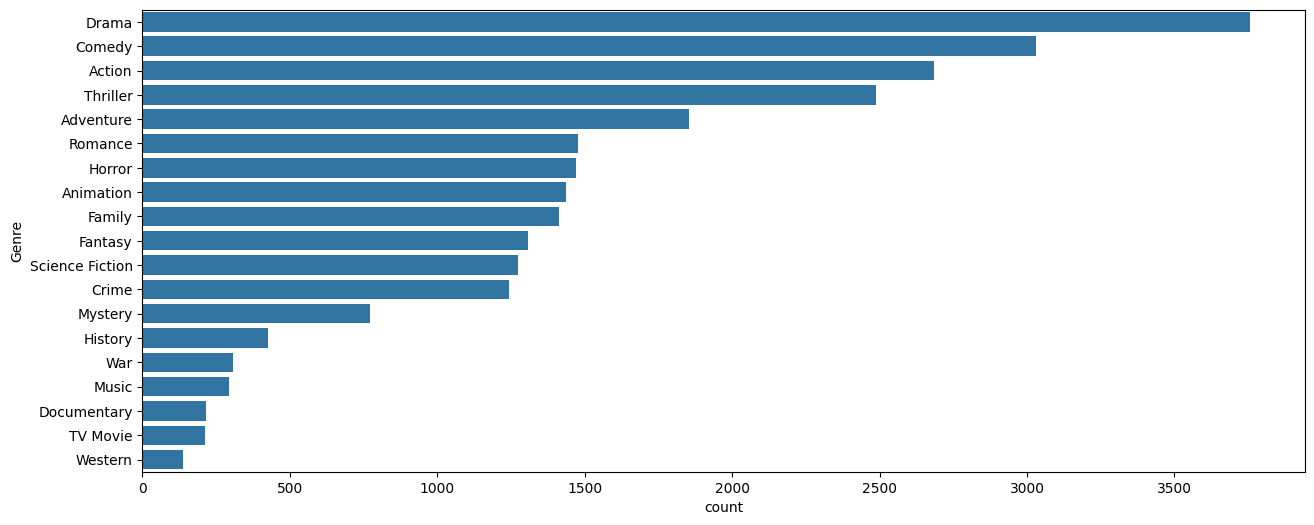

In [ ]:
plt.figure(figsize=(15,6))
sns.countplot(y=dataset['Genre'],order=dataset['Genre'].value_counts().index)

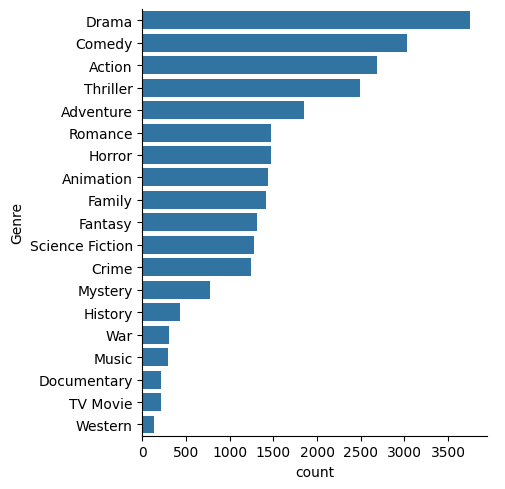

In [ ]:
sns.catplot(y='Genre',data=dataset,kind='count',order=dataset['Genre'].value_counts().index)

In [ ]:
dataset.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
0,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Action,Popular
1,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Adventure,Popular
2,2021,Spider-Man: No Way Home,5083.954,8940.0,8.3,Science Fiction,Popular
3,2022,The Batman,3827.658,1151.0,8.1,Crime,Popular
4,2022,The Batman,3827.658,1151.0,8.1,Mystery,Popular


In [ ]:
dataset['Popularity'].idxmax()

0

In [ ]:
dataset.loc(0)

In [ ]:
dataset['Vote_Average'].idxmax()

24766

In [ ]:
dataset.iloc[24766]

,24766
Release_Date,2020
Title,Kung Fu Master Huo Yuanjia
Popularity,13.745
Vote_Count,1.0
Vote_Average,10.0
Genre,Action
Quality,Popular


In [ ]:
dataset[dataset['Popularity']==dataset['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Quality
3144,2006,61.328,7.1,1391.527552,6.439427,Drama,Average


<Axes: >

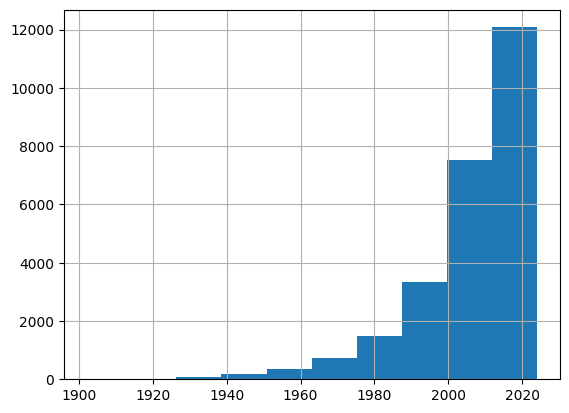

In [ ]:
dataset['Release_Date'].hist()